# Daegu Residential Property Price Prediction

## Project Overview

Property prices in Daegu vary significantly depending on location, size, building age, and housing type. Buyers, sellers, and agents currently have no simple, data-driven way to estimate a fair transaction price directly from these attributes, they rely on manually comparing similar recent sales, which is slow and inconsistent across the city's many districts. This project uses two decades of recorded transaction data (August 2005 to December 2024) to answer one central question:

**What does a residential property in Daegu sell for, given its location, size, age, and housing type, and which of these factors matter most in predicting that price?**

To answer this, the analysis looks at:
- How location (district, sub-locality) relates to transaction price
- How structural attributes (exclusive area, floor, building age) relate to price
- Whether price patterns and price drivers differ across housing types
- Which model predicts price most reliably, validated in a way that reflects predicting *future* transactions rather than re-guessing past ones

**Goal:** Build a regression model that predicts transaction price from a property's recorded attributes, covering all five housing types, and identify which attributes most strongly influence price, with performance reported both overall and per housing type.

**Stakeholder:** Prospective buyers, sellers, and real estate agents in Daegu, as well as market analysts studying long-term pricing trends.

**Data Source:** Daegu residential property transaction records (August 2005 to December 2024), containing 740,480 transactions across apartment, single-family, row house/multiplex, multi-family, and officetel housing types, sourced from Korea's Ministry of Land, Infrastructure and Transport via the Public Data Portal (KOGL Type 1 license, attribution required).

**Tools Used:** Python (pandas, numpy, scikit-learn, xgboost, matplotlib, seaborn, scipy) in Jupyter Notebook via VS Code.

**Evaluation Metric:** RMSE and MAE to measure typical prediction error in the target's own unit (10,000 KRW), and MAPE to check whether accuracy holds up as a percentage across both low-value and high-value properties, since prices in this data range from 236 to 1,800,000.

**Scope:** This analysis covers all five housing types present in the data, rather than apartments only. Housing types are strongly imbalanced (apartments make up 552,026 of 740,480 records, officetels only 8,082), so results are reported both overall and by housing type. Because the data spans 20 years of market history, model validation uses a time-based split rather than a random split, to reflect predicting prices for new, future transactions.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

pd.set_option("display.max_columns", None)

In [2]:
plt.rcParams["font.family"] = "Noto Serif"
plt.rcParams["figure.facecolor"] = "#191919"
plt.rcParams["figure.edgecolor"] = "#191919"
plt.rcParams["axes.facecolor"] = "#191919"
plt.rcParams["savefig.facecolor"] = "#191919"
plt.rcParams["savefig.edgecolor"] = "#191919"
plt.rcParams["text.color"] = "#FAFAFA"
plt.rcParams["axes.labelcolor"] = "#FAFAFA"
plt.rcParams["axes.titlecolor"] = "#FAFAFA"
plt.rcParams["axes.edgecolor"] = "#FAFAFA"
plt.rcParams["xtick.color"] = "#FAFAFA"
plt.rcParams["ytick.color"] = "#FAFAFA"
plt.rcParams["grid.color"] = "#3A3A3A"

ACCENT = "#8F002F"
DIM = "#4B4B4B"

## Data Understanding and Cleaning

In [3]:
df = pd.read_csv("../data/raw/Daegu_apt.csv")

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
df.head()

C:\Users\winte\AppData\Local\Temp\ipykernel_25064\3209153767.py:1: DtypeWarning: Columns (9: building_block, 19: transaction_type) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/raw/Daegu_apt.csv")


Rows: 740,480
Columns: 21


,ID,city,county_or_gu,sub_locality,address_number,main_number,sub_number,road_name,building_name,building_block,floor,exclusive_area_m2,total_area_m2,land_area_m2,land_ownership_area_m2,construction_year,contract_year_month,contract_day,housing_type,transaction_type,transaction_price_krw_10k
0,11,대구광역시,서구,비산동,NaN,NaN,NaN,달서천로49길,NaN,NaN,NaN,NaN,150.62,125.3,NaN,1991.0,200508,19,단독,NaN,7950
1,14,대구광역시,남구,대명동,NaN,NaN,NaN,골안길,NaN,NaN,NaN,NaN,185.06,224.1,NaN,1976.0,200508,25,단독,NaN,19500
2,16,대구광역시,북구,복현동,368-1,368.0,1.0,동북로65길 13,광명,NaN,5.0,46.625,NaN,NaN,NaN,1980.0,200510,1,아파트,NaN,3250
3,19,대구광역시,수성구,범물동,1261,1261.0,0.0,용학로 336,범물하이츠,NaN,6.0,41.850,NaN,NaN,NaN,1992.0,200510,1,아파트,NaN,4000
4,3,대구광역시,달성군,화원읍 천내리,118,118.0,0.0,화원로 36,화원창신맨션,NaN,1.0,84.990,NaN,NaN,NaN,1990.0,200510,10,아파트,NaN,5950


In [4]:
category_cols = ["housing_type", "county_or_gu", "sub_locality", "transaction_type"]
df[category_cols] = df[category_cols].astype("category")

df.dtypes

ID                              int64
city                              str
county_or_gu                 category
sub_locality                 category
address_number                    str
main_number                   float64
sub_number                    float64
road_name                         str
building_name                     str
building_block                    str
floor                         float64
exclusive_area_m2             float64
total_area_m2                 float64
land_area_m2                  float64
land_ownership_area_m2        float64
construction_year             float64
contract_year_month             int64
contract_day                    int64
housing_type                 category
transaction_type             category
transaction_price_krw_10k       int64
dtype: object

### Selecting Relevant Columns

This analysis predicts price from a property's structural and location attributes. `city` is dropped, it has a single constant value across all 740,480 rows and carries no information. Address-level identifiers (`address_number`, `main_number`, `sub_number`, `building_block`) are also dropped, they identify a specific lot or unit but don't generalize to properties the model hasn't seen before, so they can't function as predictive features.

In [5]:
drop_cols = ["city", "address_number", "main_number", "sub_number", "building_block"]
df = df.drop(columns=drop_cols)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 740480 entries, 0 to 740479
Data columns (total 16 columns):
 #   Column                     Non-Null Count   Dtype   
---  ------                     --------------   -----   
 0   ID                         740480 non-null  int64   
 1   county_or_gu               740480 non-null  category
 2   sub_locality               740433 non-null  category
 3   road_name                  733559 non-null  str     
 4   building_name              625273 non-null  str     
 5   floor                      625273 non-null  float64 
 6   exclusive_area_m2          625273 non-null  float64 
 7   total_area_m2              115207 non-null  float64 
 8   land_area_m2               115207 non-null  float64 
 9   land_ownership_area_m2     65165 non-null   float64 
 10  construction_year          738882 non-null  float64 
 11  contract_year_month        740480 non-null  int64   
 12  contract_day               740480 non-null  int64   
 13  housing_type             

Before deciding how to treat missing values, we first need to know whether they are random or follow a pattern. The next cells measure how much is missing in each column, test whether the gaps line up with housing type or with time, and check for duplicate rows.

In [6]:
missing_summary = (
    df.isna().sum().to_frame("missing_count")
    .assign(missing_pct=lambda d: (d["missing_count"] / len(df) * 100).round(2))
    .sort_values("missing_pct", ascending=False)
)
missing_summary

,missing_count,missing_pct
land_ownership_area_m2,675315,91.20
transaction_type,670173,90.51
total_area_m2,625273,84.44
land_area_m2,625273,84.44
building_name,115207,15.56
exclusive_area_m2,115207,15.56
floor,115207,15.56
road_name,6921,0.93
construction_year,1598,0.22
sub_locality,47,0.01


In [7]:
df["has_exclusive_area"] = df["exclusive_area_m2"].notna()
df["has_total_area"] = df["total_area_m2"].notna()

print(pd.crosstab(df["housing_type"], df["has_exclusive_area"]))
print()
print(pd.crosstab(df["housing_type"], df["has_total_area"]))

has_exclusive_area  False   True 
housing_type                     
다가구                 27250       0
단독                  87957       0
아파트                     0  552026
연립/다세대                  0   65165
오피스텔                    0    8082

has_total_area   False  True 
housing_type                 
다가구                  0  27250
단독                   0  87957
아파트             552026      0
연립/다세대           65165      0
오피스텔              8082      0


In [8]:
df["has_land_ownership"] = df["land_ownership_area_m2"].notna()
print(pd.crosstab(df["housing_type"], df["has_land_ownership"]))

has_land_ownership   False  True 
housing_type                     
다가구                  27250      0
단독                   87957      0
아파트                 552026      0
연립/다세대                   0  65165
오피스텔                  8082      0


In [9]:
df["has_transaction_type"] = df["transaction_type"].notna()
print(pd.crosstab(df["housing_type"], df["has_transaction_type"]))

df["contract_year"] = df["contract_year_month"] // 100
print()
print(df.groupby("contract_year", observed=True)["has_transaction_type"].mean().round(3))

has_transaction_type   False  True 
housing_type                       
다가구                    25911   1339
단독                     84124   3833
아파트                   492963  59063
연립/다세대                 60863   4302
오피스텔                    6312   1770

contract_year
2005    0.000
2006    0.000
2007    0.000
2008    0.000
2009    0.000
2010    0.000
2011    0.000
2012    0.000
2013    0.000
2014    0.000
2015    0.000
2016    0.000
2017    0.000
2018    0.000
2019    0.000
2020    0.000
2021    0.123
2022    1.000
2023    1.000
2024    1.000
Name: has_transaction_type, dtype: float64


In [10]:
print("Fully duplicate rows:", df.duplicated().sum())
print("Duplicate ID values:", df["ID"].duplicated().sum())

Fully duplicate rows: 0
Duplicate ID values: 0


### Data Quality Findings

- No duplicate rows and no duplicate `ID` values were found across all 740,480 records.
- `exclusive_area_m2`, `floor`, and `building_name` are missing for exactly the same 115,207 rows (15.56%), and `total_area_m2`/`land_area_m2` are missing for exactly the other 625,273 rows. This is not random missing data, it reflects two different recording conventions: Apartment, Row house/Multiplex, and Officetel transactions record a unit's exclusive area, while Single-family and Multi-family transactions record whole-building and land area instead, property types that don't have a per-unit "exclusive area" to report. These will be reconciled into one comparable feature rather than imputed.
- `land_ownership_area_m2` (91.20% missing) is recorded only for Row house/Multiplex transactions (65,165 of 65,165), and is absent for every other housing type. Same structural pattern as above, specific to one housing type's recording convention.
- `transaction_type` (90.51% missing) is not explained by housing type, it is explained by time. The field has 0% coverage for every year from 2005 through 2020, rises to 12.3% partway through 2021, and reaches 100% coverage from 2022 onward. This indicates a disclosure requirement that was introduced in 2021, transactions before then have no `transaction_type` because the field did not yet exist for them, this is a structural gap in the data source, not something to impute.
- `road_name` (0.93%), `construction_year` (0.22%), and `sub_locality` (0.01%) have low, low-impact missingness with no structural pattern identified, these are small enough to drop the affected rows without meaningfully reducing the dataset.

### Handling Missing Data

`exclusive_area_m2` and `total_area_m2` are reconciled into one `area_m2` feature (using whichever is recorded per row), with an `area_source` flag noting which convention applied, rather than kept as two sparse columns. `land_area_m2`, `land_ownership_area_m2`, and `transaction_type` are dropped rather than imputed, each is structurally tied to a specific housing type or time period (see Data Quality Findings) rather than randomly missing, so there is no reliable value to impute. `road_name` and `building_name` are dropped for being too high-cardinality to generalize as model features. Rows missing `construction_year` or `sub_locality` (0.22% and 0.01% respectively) are dropped, with no structural pattern behind either, removing them is simpler than imputing and has negligible impact on the dataset size.

In [11]:
df["area_m2"] = df["exclusive_area_m2"].fillna(df["total_area_m2"])
df["area_source"] = np.where(df["exclusive_area_m2"].notna(), "exclusive", "total")

df = df.drop(columns=[
    "exclusive_area_m2", "total_area_m2", "land_area_m2", "land_ownership_area_m2",
    "transaction_type", "road_name", "building_name",
    "has_exclusive_area", "has_total_area", "has_land_ownership", "has_transaction_type"
])

df = df.dropna(subset=["construction_year", "sub_locality"])

print(f"Rows remaining: {df.shape[0]:,}")
df.info()

Rows remaining: 738,836
<class 'pandas.DataFrame'>
Index: 738836 entries, 0 to 740479
Data columns (total 12 columns):
 #   Column                     Non-Null Count   Dtype   
---  ------                     --------------   -----   
 0   ID                         738836 non-null  int64   
 1   county_or_gu               738836 non-null  category
 2   sub_locality               738836 non-null  category
 3   floor                      625250 non-null  float64 
 4   construction_year          738836 non-null  float64 
 5   contract_year_month        738836 non-null  int64   
 6   contract_day               738836 non-null  int64   
 7   housing_type               738836 non-null  category
 8   transaction_price_krw_10k  738836 non-null  int64   
 9   contract_year              738836 non-null  int64   
 10  area_m2                    738836 non-null  float64 
 11  area_source                738836 non-null  str     
dtypes: category(3), float64(3), int64(5), str(1)
memory usage: 65.2 

`floor` follows the same housing-type-driven pattern as the area columns: it is only recorded for Apartment, Row house/Multiplex, and Officetel transactions, since Single-family and Multi-family properties are not divided into floors in the same sense. Rather than inventing a sentinel value for "not applicable," `floor` is dropped from the feature set, `housing_type` and `area_m2` already carry this structural distinction.

In [12]:
df = df.drop(columns=["floor"])

print(f"Rows remaining: {df.shape[0]:,}")
df.info()

Rows remaining: 738,836
<class 'pandas.DataFrame'>
Index: 738836 entries, 0 to 740479
Data columns (total 11 columns):
 #   Column                     Non-Null Count   Dtype   
---  ------                     --------------   -----   
 0   ID                         738836 non-null  int64   
 1   county_or_gu               738836 non-null  category
 2   sub_locality               738836 non-null  category
 3   construction_year          738836 non-null  float64 
 4   contract_year_month        738836 non-null  int64   
 5   contract_day               738836 non-null  int64   
 6   housing_type               738836 non-null  category
 7   transaction_price_krw_10k  738836 non-null  int64   
 8   contract_year              738836 non-null  int64   
 9   area_m2                    738836 non-null  float64 
 10  area_source                738836 non-null  str     
dtypes: category(3), float64(2), int64(5), str(1)
memory usage: 59.6 MB


### Translating Categorical Labels

`housing_type` values are translated from Korean to English, since they describe a property category (a meaningful translation, not just a name). `county_or_gu` values are romanized using their official English district names, since these are proper place names, not something to translate literally.

In [13]:
housing_type_map = {
    "아파트": "Apartment",
    "단독": "Single-family",
    "연립/다세대": "Row house/Multiplex",
    "다가구": "Multi-family",
    "오피스텔": "Officetel",
}

gu_map = {
    "중구": "Jung-gu",
    "동구": "Dong-gu",
    "서구": "Seo-gu",
    "남구": "Nam-gu",
    "북구": "Buk-gu",
    "수성구": "Suseong-gu",
    "달서구": "Dalseo-gu",
    "달성군": "Dalseong-gun",
    "군위군": "Gunwi-gun",
}

df["housing_type"] = df["housing_type"].map(housing_type_map).astype("category")
df["county_or_gu"] = df["county_or_gu"].map(gu_map).astype("category")

print(df["housing_type"].isna().sum(), "unmapped housing_type values")
print(df["county_or_gu"].isna().sum(), "unmapped county_or_gu values")
print()
print(df["housing_type"].value_counts())
print()
print(df["county_or_gu"].value_counts())

0 unmapped housing_type values
0 unmapped county_or_gu values

housing_type
Apartment              552016
Single-family           86697
Row house/Multiplex     65165
Multi-family            26889
Officetel                8069
Name: count, dtype: int64

county_or_gu
Dalseo-gu       177667
Buk-gu          141120
Suseong-gu      130075
Dong-gu         105188
Dalseong-gun     68940
Seo-gu           49033
Nam-gu           40424
Jung-gu          23669
Gunwi-gun         2720
Name: count, dtype: int64


### Feature Engineering

`property_age` is derived as `contract_year` minus `construction_year`, giving the building's age at the time of sale rather than two separate absolute years, a more directly useful signal for price. `area_source` is dropped, it was created only to reconcile the two original area columns and is redundant with `housing_type` (see the crosstab in Data Understanding), keeping both would let the model see the same structural split twice under different names.

In [14]:
df["property_age"] = df["contract_year"] - df["construction_year"]
df = df.drop(columns=["area_source"])

df["property_age"].describe()

count    738836.000000
mean         16.357323
std          12.857037
min          -3.000000
25%           7.000000
50%          15.000000
75%          23.000000
max        2022.000000
Name: property_age, dtype: float64

The age summary above shows two impossible values: a minimum of -3 years and a maximum of 2022 years. The next three cells investigate both. First we count the negative ages, then we look at the construction years behind the extreme high ages, checking whether specific values (such as 0 or 1900) appear far more often than their neighbors, which would signal placeholder entries rather than real dates.

In [15]:
negative_age = df[df["property_age"] < 0]
print(f"Rows with negative property_age: {len(negative_age):,} ({len(negative_age) / len(df) * 100:.2f}%)")
negative_age[["housing_type", "construction_year", "contract_year", "property_age"]].head(10)

Rows with negative property_age: 48 (0.01%)


,housing_type,construction_year,contract_year,property_age
58594,Row house/Multiplex,2008.0,2007,-1.0
149225,Officetel,2013.0,2010,-3.0
221095,Multi-family,2012.0,2011,-1.0
322564,Row house/Multiplex,2014.0,2013,-1.0
322568,Row house/Multiplex,2014.0,2013,-1.0
322574,Row house/Multiplex,2014.0,2013,-1.0
322575,Row house/Multiplex,2014.0,2013,-1.0
322578,Row house/Multiplex,2014.0,2013,-1.0
322582,Row house/Multiplex,2014.0,2013,-1.0
322587,Row house/Multiplex,2014.0,2013,-1.0


In [16]:
print(df["construction_year"].describe())
print()
top_age = df.sort_values("property_age", ascending=False).head(10)
top_age[["housing_type", "construction_year", "contract_year", "property_age"]]

count    738836.000000
mean       1998.345437
std          12.731262
min           0.000000
25%        1992.000000
50%        1999.000000
75%        2007.000000
max        2024.000000
Name: construction_year, dtype: float64



,housing_type,construction_year,contract_year,property_age
684953,Single-family,0.0,2022,2022.0
615314,Single-family,0.0,2020,2020.0
490118,Single-family,0.0,2017,2017.0
99543,Single-family,0.0,2009,2009.0
715725,Single-family,990.0,2024,1034.0
723553,Single-family,1900.0,2024,124.0
732359,Single-family,1900.0,2024,124.0
732333,Single-family,1900.0,2024,124.0
715734,Single-family,1900.0,2024,124.0
715600,Single-family,1900.0,2024,124.0


In [17]:
print("Rows with construction_year == 0:", (df["construction_year"] == 0).sum())
print("Rows with construction_year == 1900:", (df["construction_year"] == 1900).sum())
print()
print(df.loc[df["construction_year"] < 1920, "construction_year"].value_counts().sort_index())

Rows with construction_year == 0: 4
Rows with construction_year == 1900: 138

construction_year
0.0         4
990.0       1
1900.0    138
1901.0     17
1902.0      5
1903.0      3
1904.0      7
1905.0     10
1906.0      2
1907.0      1
1908.0      5
1909.0      9
1910.0     26
1911.0      2
1912.0      8
1913.0     10
1914.0     10
1915.0     12
1916.0      4
1917.0      3
1918.0      4
1919.0      5
Name: count, dtype: int64


### Correcting Construction Year Anomalies

`construction_year` contains three invalid patterns: `0` (4 rows, an obviously invalid placeholder), `990` (1 row, likely a typo for 1990, but not corrected since it can't be verified), and `1900` (138 rows, a frequency roughly 5 to 10 times higher than any neighboring year, indicating a reused placeholder for "very old, exact year unknown" rather than genuine recorded dates). All three patterns combined affect only 143 rows (0.02% of the data) and are dropped rather than guessed at.

Separately, 48 rows (0.01%) show a negative `property_age`, a property sold before its listed construction year. This is consistent with Korea's common practice of pre-sale transactions (분양권), where a unit is sold based on blueprints before construction is finished. These rows are kept, with `property_age` capped at 0 rather than left negative, treating "sold before completion" as effectively age zero.

In [18]:
bad_construction_years = [0, 990, 1900]
df = df[~df["construction_year"].isin(bad_construction_years)]

df["property_age"] = df["property_age"].clip(lower=0)

print(f"Rows remaining: {df.shape[0]:,}")
df["property_age"].describe()

Rows remaining: 738,693


count    738693.000000
mean         16.326458
std          11.847967
min           0.000000
25%           7.000000
50%          15.000000
75%          23.000000
max         120.000000
Name: property_age, dtype: float64

In [19]:
print(df.loc[df["property_age"] > 80, "construction_year"].value_counts().sort_index())

construction_year
1901.0    17
1902.0     5
1903.0     3
1904.0     7
1905.0    10
1906.0     2
1907.0     1
1908.0     5
1909.0     9
1910.0    26
1911.0     2
1912.0     8
1913.0    10
1914.0    10
1915.0    12
1916.0     4
1917.0     3
1918.0     4
1919.0     5
1920.0    67
1921.0     9
1922.0     4
1923.0    11
1924.0    38
1925.0    72
1926.0    27
1927.0     7
1928.0    14
1929.0    14
1930.0    69
1931.0     8
1932.0     4
1933.0     2
1934.0    13
1935.0    23
1936.0     6
1937.0     4
1938.0     4
1939.0     1
1940.0    16
1941.0     1
1942.0     1
Name: count, dtype: int64


Ages above 80 years show a pattern of "age heaping," construction years clustering on round decade-marks (1920, 1925, 1930, 1940) more than nearby years. This reflects imprecise recording of old buildings' construction years (likely rounded to the nearest 5 or 10 by whoever recorded them decades ago), rather than a single fabricated placeholder like the `1900`/`0`/`990` cases above. These rows are kept as-is, this imprecision is noted as a data limitation rather than corrected, since there is no reliable way to recover the true year.

### Checkpoint

The cleaned and feature-engineered dataset is saved as a checkpoint before moving into analysis. Saved as pickle rather than CSV to preserve dtypes (category, float64) and avoid the parquet engine dependency (pyarrow/fastparquet) entirely.

In [20]:
df.to_pickle("../data/processed/daegu_apt_cleaned.pkl")

print(f"Saved {df.shape[0]:,} rows, {df.shape[1]} columns")
df.dtypes

Saved 738,693 rows, 11 columns


ID                              int64
county_or_gu                 category
sub_locality                 category
construction_year             float64
contract_year_month             int64
contract_day                    int64
housing_type                 category
transaction_price_krw_10k       int64
contract_year                   int64
area_m2                       float64
property_age                  float64
dtype: object

## Exploratory Data Analysis

### Target Variable Distribution

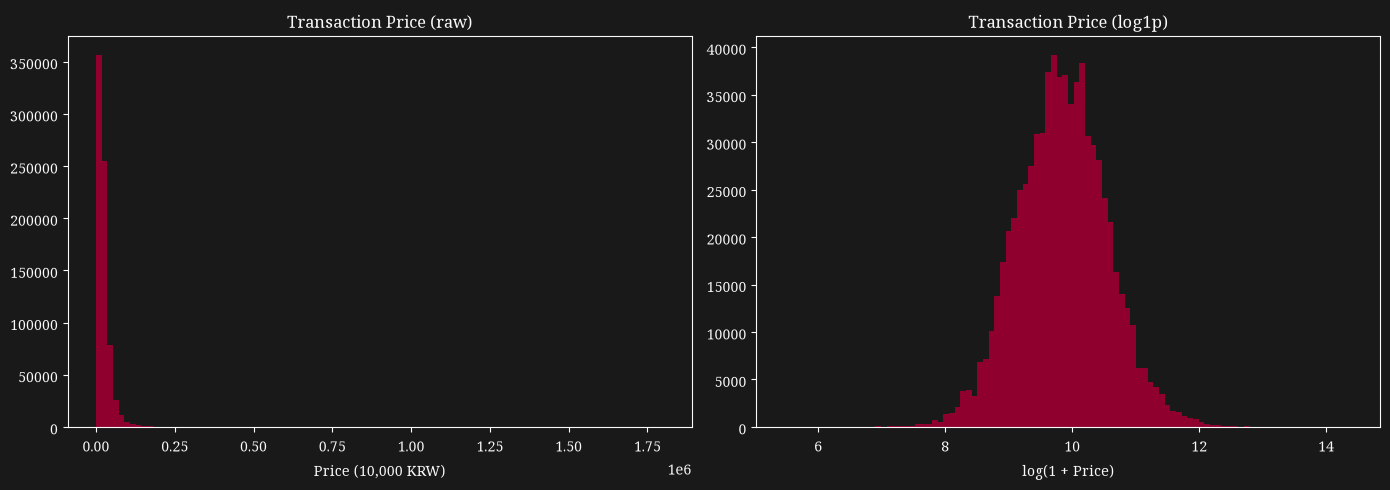

Skewness (raw): 7.729335237948125
Skewness (log1p): 0.04750983929590988


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df["transaction_price_krw_10k"], bins=100, color=ACCENT)
axes[0].set_title("Transaction Price (raw)")
axes[0].set_xlabel("Price (10,000 KRW)")

log_price = np.log1p(df["transaction_price_krw_10k"])
axes[1].hist(log_price, bins=100, color=ACCENT)
axes[1].set_title("Transaction Price (log1p)")
axes[1].set_xlabel("log(1 + Price)")

plt.tight_layout()
plt.savefig("../reports/figures/price_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print("Skewness (raw):", stats.skew(df["transaction_price_krw_10k"]))
print("Skewness (log1p):", stats.skew(log_price))

Transaction price is extremely right-skewed in its raw form (skewness = 7.73), with the vast majority of transactions concentrated at low values and a long tail of high-value sales stretching toward 1.8 million (10,000 KRW units). A log1p transform corrects this almost completely (skewness = 0.05), producing an approximately symmetric distribution. Modeling will use log-transformed price as the target, and predictions will be converted back to the original scale (via expm1) for reporting and evaluation.

### Price by Housing Type

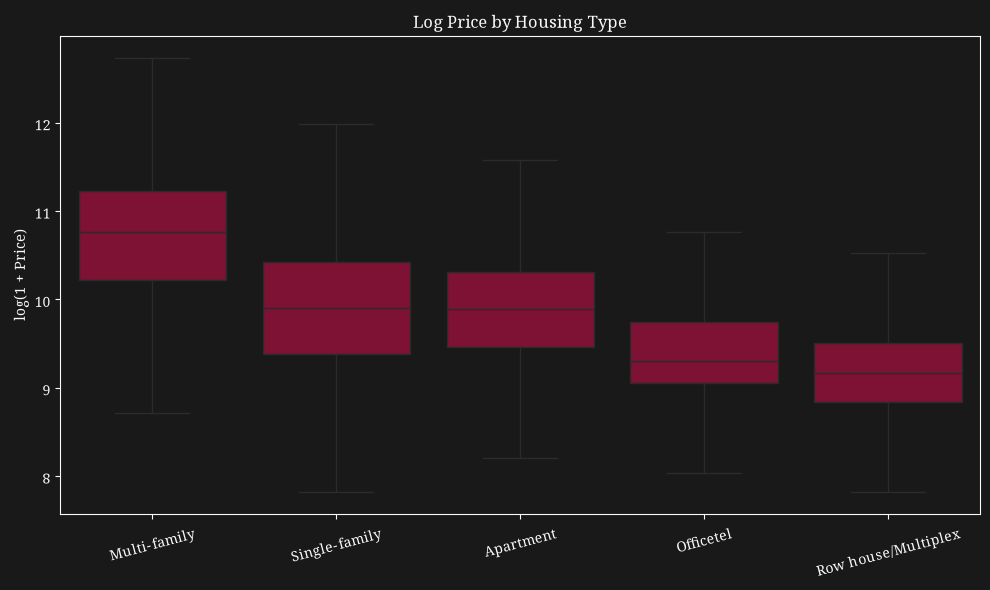

,count,mean,std,min,25%,50%,75%,max
housing_type,,,,,,,,
Multi-family,26881.0,56411.582754,41410.197968,1125.0,27400.0,47500.0,75000.0,1192000.0
Single-family,86562.0,28764.118251,35783.427406,236.0,11822.0,19995.0,33570.0,1800000.0
Apartment,552016.0,23900.223405,16735.060048,1000.0,12900.0,19800.0,30000.0,540000.0
Row house/Multiplex,65165.0,11397.341410,8105.566961,400.0,6870.0,9550.0,13500.0,265365.0
Officetel,8069.0,13342.473417,7479.584154,1750.0,8600.0,11000.0,17000.0,80000.0


In [22]:
order = df.groupby("housing_type", observed=True)["transaction_price_krw_10k"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(10, 6))
log_price_by_type = df.assign(log_price=np.log1p(df["transaction_price_krw_10k"]))

sns.boxplot(
    data=log_price_by_type, x="housing_type", y="log_price", order=order,
    ax=ax, color=ACCENT, showfliers=False
)
ax.set_title("Log Price by Housing Type")
ax.set_xlabel("")
ax.set_ylabel("log(1 + Price)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("../reports/figures/price_by_housing_type.png", dpi=150, bbox_inches="tight")
plt.show()

df.groupby("housing_type", observed=True)["transaction_price_krw_10k"].describe()

In [23]:
df["price_per_m2"] = df["transaction_price_krw_10k"] / df["area_m2"]

df.groupby("housing_type", observed=True)["price_per_m2"].describe()

,count,mean,std,min,25%,50%,75%,max
housing_type,,,,,,,,
Multi-family,26881.0,177.774125,126.542444,8.531039,114.400769,154.491065,207.506084,5112.416447
Single-family,86562.0,247.669846,288.772390,5.148774,107.563628,167.313095,276.132399,9993.570348
Apartment,552016.0,290.547507,148.094345,22.609089,189.466466,262.843489,348.958159,2244.317202
Row house/Multiplex,65165.0,180.074096,107.938715,14.551804,114.197531,155.657823,210.426640,3161.497084
Officetel,8069.0,319.301169,113.395949,41.044776,237.665463,322.684737,388.514110,945.514715


Housing types differ substantially in raw price (Multi-family highest median at 47,500, Row house/Multiplex lowest at 9,550), which explains the secondary peak seen in the earlier log-price histogram. However, ranking housing types by raw price is misleading: since `area_m2` represents a single unit's area for Apartment, Row house/Multiplex, and Officetel, but a whole building's area for Single-family and Multi-family (see Feature Engineering), Multi-family's high total price partly reflects that it's a larger, whole-building purchase, not necessarily higher value per square meter. Price per square meter tells a different story: Apartment (median 262.84) and Officetel (median 322.68) rank highest, while Multi-family (154.49) and Row house/Multiplex (155.66) rank lowest. This inconsistency in what `area_m2` represents across housing types is a real modeling consideration, addressed via `housing_type` interactions or tree-based models that can split on housing type naturally, rather than assuming one uniform price-per-area relationship.

### Price Trend Over Time

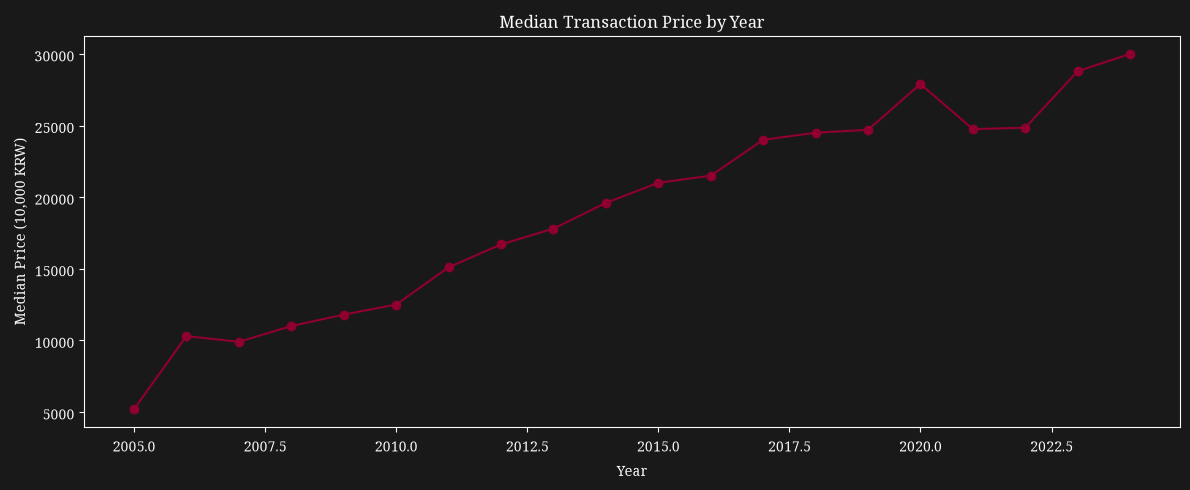

contract_year
2005     5200.0
2006    10300.0
2007     9900.0
2008    11000.0
2009    11800.0
2010    12500.0
2011    15100.0
2012    16700.0
2013    17800.0
2014    19600.0
2015    21000.0
2016    21500.0
2017    24000.0
2018    24500.0
2019    24700.0
2020    27900.0
2021    24750.0
2022    24850.0
2023    28800.0
2024    30000.0
Name: transaction_price_krw_10k, dtype: float64

In [24]:
yearly = df.groupby("contract_year")["transaction_price_krw_10k"].median()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(yearly.index, yearly.values, color=ACCENT, marker="o")
ax.set_title("Median Transaction Price by Year")
ax.set_xlabel("Year")
ax.set_ylabel("Median Price (10,000 KRW)")
plt.tight_layout()
plt.savefig("../reports/figures/price_trend_over_time.png", dpi=150, bbox_inches="tight")
plt.show()

yearly

In [25]:
df.groupby("contract_year").size()

contract_year
2005       21
2006    30160
2007    28810
2008    30013
2009    39395
2010    40049
2011    54576
2012    47709
2013    52891
2014    50280
2015    49023
2016    29039
2017    42248
2018    44370
2019    42400
2020    62049
2021    28955
2022    14545
2023    24992
2024    27168
dtype: int64

2005 contains only 21 transactions (versus 28,000+ in every other year), reflecting that the disclosure system's records begin partway through the year (August 2005 per the dataset's original documentation), not a real annual price level. This near-empty year is dropped rather than kept, at 21 rows the loss is negligible, but leaving it in risks distorting any time-based trend feature or split, since it would sit as an extreme, unrepresentative point at the very edge of the time range.

In [26]:
df = df[df["contract_year"] != 2005]

print(f"Rows remaining: {df.shape[0]:,}")
df["contract_year"].min(), df["contract_year"].max()

Rows remaining: 738,672


(np.int64(2006), np.int64(2024))

Median transaction price rose consistently from 2006 (10,300) to 2024 (30,000), roughly a 3x increase over 19 years, real, sustained market growth rather than noise, this supports using `contract_year` as a meaningful predictive feature and confirms the time-based validation split from the Project Overview is necessary, a random split would blend early, much cheaper transactions with recent ones in both train and test sets. One dip is visible: prices fell from a 2020 peak (27,900) to 24,750-24,850 through 2021-2022, before recovering in 2023-2024. This coincides with a genuine drop in transaction volume over the same period (28,955 in 2021 and 14,545 in 2022, versus 42,000-62,000 in surrounding years), consistent with a real market slowdown (rate-driven cooling following the 2020 boom) rather than a data quality issue.

### Price by Location

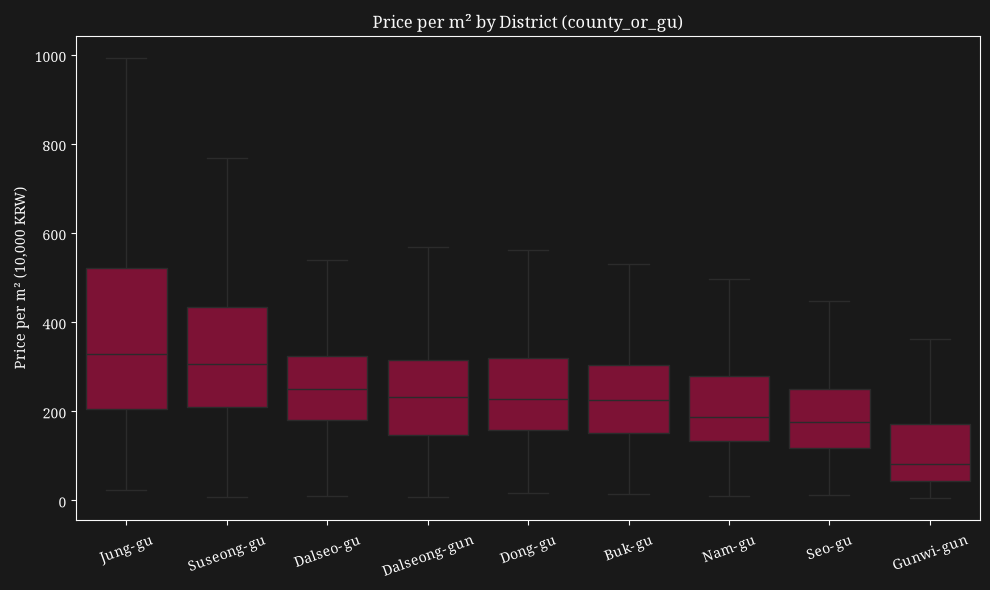

,count,mean,std,min,25%,50%,75%,max
county_or_gu,,,,,,,,
Gunwi-gun,2712.0,114.556536,99.342635,5.148774,41.681984,80.574126,170.257082,980.392157
Nam-gu,40402.0,228.776253,173.943164,9.172064,132.193039,187.189933,277.706087,5810.575247
Dalseo-gu,177651.0,270.347417,131.377255,8.531039,179.453989,249.074955,323.529412,6408.766079
Dalseong-gun,68907.0,239.940061,124.851377,6.186843,145.048349,231.207019,314.215370,4000.703083
Dong-gu,105161.0,253.142065,144.786378,15.684224,156.593407,225.924182,318.260711,8691.965232
Buk-gu,141109.0,245.495959,139.221600,13.774948,150.659134,225.037506,302.228769,7496.325331
Seo-gu,49002.0,195.933116,111.417218,12.135922,117.752302,174.324188,249.645844,3465.634921
Suseong-gu,130068.0,358.530785,225.375178,6.688963,209.757247,305.274900,433.115493,5817.335660
Jung-gu,23660.0,393.143916,302.649455,23.217247,204.415372,327.673178,520.100568,9993.570348


In [27]:
order = df.groupby("county_or_gu", observed=True)["price_per_m2"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(
    data=df, x="county_or_gu", y="price_per_m2", order=order,
    ax=ax, color=ACCENT, showfliers=False
)
ax.set_title("Price per m² by District (county_or_gu)")
ax.set_xlabel("")
ax.set_ylabel("Price per m² (10,000 KRW)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("../reports/figures/price_by_district.png", dpi=150, bbox_inches="tight")
plt.show()

df.groupby("county_or_gu", observed=True)["price_per_m2"].describe()

The boxplot hides outliers on purpose, but the table below it shows that in most districts the maximum price per m2 is more than ten times the 75th percentile. The next cells check whether these extreme values come from unusually small areas, and which housing types and districts they belong to.

In [28]:
print(df["area_m2"].describe())
print()
extreme = df.sort_values("price_per_m2", ascending=False).head(10)
extreme[["housing_type", "county_or_gu", "area_m2", "transaction_price_krw_10k", "price_per_m2"]]

count    738672.000000
mean         94.273640
std          78.501014
min           3.310000
25%          59.870000
50%          83.850000
75%          84.998000
max       13667.740000
Name: area_m2, dtype: float64



,housing_type,county_or_gu,area_m2,transaction_price_krw_10k,price_per_m2
654473,Single-family,Jung-gu,26.44,264230,9993.570348
711293,Single-family,Dong-gu,47.17,410000,8691.965232
624347,Single-family,Buk-gu,40.82,306000,7496.325331
577108,Single-family,Jung-gu,15.63,113000,7229.686500
674494,Single-family,Dong-gu,72.40,500000,6906.077348
607611,Single-family,Buk-gu,28.46,190000,6676.036543
576513,Single-family,Dalseo-gu,20.99,134520,6408.766079
606735,Single-family,Buk-gu,47.70,300000,6289.308176
348405,Single-family,Jung-gu,24.79,152000,6131.504639
554350,Single-family,Suseong-gu,17.19,100000,5817.335660


In [29]:
extreme_rows = df.sort_values("price_per_m2", ascending=False).head(30)

print(extreme_rows["area_m2"].describe())
print()
print(extreme_rows["housing_type"].value_counts())
print()
print(extreme_rows["county_or_gu"].value_counts())

count    30.000000
mean     39.845667
std      21.509893
min      10.810000
25%      24.817500
50%      38.260000
75%      46.947500
max      98.740000
Name: area_m2, dtype: float64

housing_type
Single-family          28
Multi-family            2
Apartment               0
Row house/Multiplex     0
Officetel               0
Name: count, dtype: int64

county_or_gu
Jung-gu         12
Dong-gu          5
Buk-gu           5
Dalseo-gu        3
Suseong-gu       3
Nam-gu           2
Gunwi-gun        0
Dalseong-gun     0
Seo-gu           0
Name: count, dtype: int64


The extreme values in the district price-per-m2 boxplot are not a data error. The 30 highest price-per-m2 transactions are almost entirely Single-family (28 of 30) and Multi-family (2 of 30) properties, small in size (mean 39.8 m2, max 98.7 m2), concentrated in central districts (12 in Jung-gu, 5 each in Dong-gu and Buk-gu). This reflects a real estate pattern where small, older houses in prime central locations are priced for their redevelopment potential rather than their current structure, so price per square meter rises rather than falls as these properties get smaller. This means the relationship between `area_m2` and price is not linear for these housing types, a plain linear model assuming one constant price-per-m2 rate will misfit them, while tree-based models can capture this through housing-type-specific splits.

### Correlation Between Numeric Features

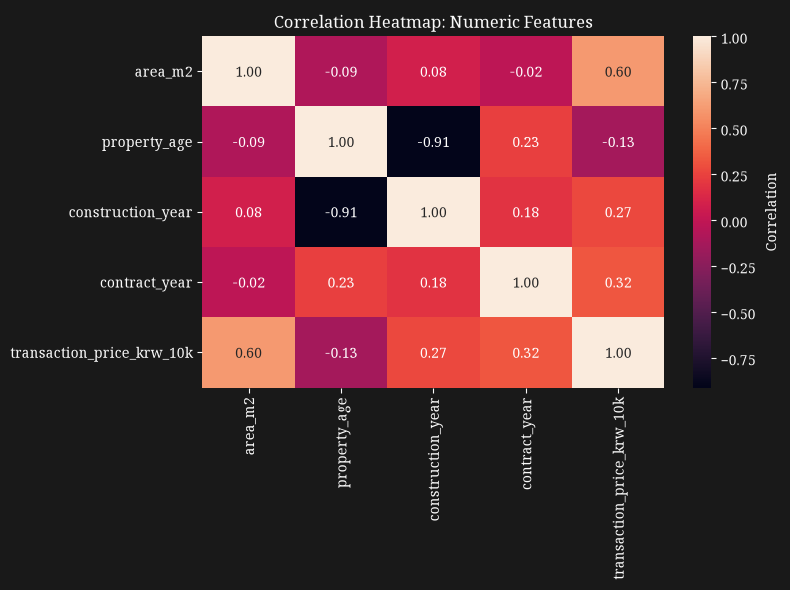

In [30]:
numeric_cols = ["area_m2", "property_age", "construction_year", "contract_year", "transaction_price_krw_10k"]

corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="rocket", ax=ax, cbar_kws={"label": "Correlation"})
ax.set_title("Correlation Heatmap: Numeric Features")
plt.tight_layout()
plt.savefig("../reports/figures/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

`property_age` and `construction_year` are near-perfectly negatively correlated (-0.91), expected since one is derived from the other, and a strong signal that both should not enter a linear model together (formally verified with VIF in Modeling). `area_m2` shows the strongest linear relationship with price (0.60), consistent with size being a primary price driver. `contract_year` correlates at 0.32, consistent with the sustained price growth trend confirmed earlier. `property_age`'s weak overall correlation with price (-0.13) undersells its real effect, EDA on housing type and location already showed that age interacts with property type and location (e.g. small Single-family houses in central districts carry a premium), a relationship a single linear correlation coefficient cannot capture, but which housing-type-aware features or tree-based models can.

### EDA Summary

Exploratory analysis established several findings that shape the modeling approach in the sections ahead:

- **Target:** `transaction_price_krw_10k` is extremely right-skewed (skewness 7.73), corrected almost completely by a log1p transform (skewness 0.05). Modeling will use log-transformed price as the target.
- **Housing type:** price levels and price-per-m2 both differ substantially by housing type, and the two rankings disagree (Multi-family has the highest raw price but a below-average price per m2), because `area_m2` represents a single unit for some housing types and a whole building for others. Performance will be evaluated per housing type, not just overall.
- **Time:** median price grew roughly 3x from 2006 to 2024, a real, sustained trend, not noise, confirming the need for a time-based train/test split. 2005 (21 rows, a partial year) was dropped as unrepresentative. A real, volume-backed price dip in 2021-2022 reflects a genuine market slowdown, not a data issue.
- **Location:** price per m2 varies meaningfully by district, consistent with Daegu's known geography (Jung-gu and Suseong-gu highest, Gunwi-gun lowest). Extreme values at the top of this distribution are not errors, they reflect small, Single-family and Multi-family properties in central districts priced for redevelopment potential, meaning `area_m2`'s relationship with price is non-linear and housing-type-dependent.
- **Multicollinearity:** `property_age` and `construction_year` are near-perfectly correlated (-0.91), one will be dropped before the linear baseline, confirmed formally with VIF in Modeling.

## Feature Encoding and Target Preparation

In [31]:
df["log_price"] = np.log1p(df["transaction_price_krw_10k"])

df[["transaction_price_krw_10k", "log_price"]].describe()

,transaction_price_krw_10k,log_price
count,7.386720e+05,738672.000000
mean,2.443543e+04,9.847340
std,2.200227e+04,0.706876
min,2.360000e+02,5.468060
25%,1.180000e+04,9.375940
50%,1.880000e+04,9.841665
75%,3.000000e+04,10.308986
max,1.800000e+06,14.403298


`housing_type` is preserved separately as `housing_type_label` before encoding, so that per-housing-type performance can still be reported after modeling, one-hot encoding would otherwise remove the readable category labels. `county_or_gu` and `housing_type` are then one-hot encoded with `drop_first=True`, dropping one category per column avoids perfect multicollinearity between dummy variables (the "dummy variable trap"), relevant for the linear baseline's VIF check in Modeling. `sub_locality` is left untouched here, its encoding will be fit on training data only, after the split in the Train/Test Split section, to avoid leakage.

In [32]:
df["housing_type"] = df["housing_type"].cat.reorder_categories(
    ["Apartment", "Multi-family", "Officetel", "Row house/Multiplex", "Single-family"]
)
df["county_or_gu"] = df["county_or_gu"].cat.reorder_categories(
    ["Dalseo-gu", "Buk-gu", "Suseong-gu", "Dong-gu", "Dalseong-gun", "Seo-gu", "Nam-gu", "Jung-gu", "Gunwi-gun"]
)

df["housing_type_label"] = df["housing_type"]

df = pd.get_dummies(df, columns=["county_or_gu", "housing_type"], drop_first=True)

print(f"Shape after encoding: {df.shape}")
df.columns.tolist()

Shape after encoding: (738672, 24)


['ID',
 'sub_locality',
 'construction_year',
 'contract_year_month',
 'contract_day',
 'transaction_price_krw_10k',
 'contract_year',
 'area_m2',
 'property_age',
 'price_per_m2',
 'log_price',
 'housing_type_label',
 'county_or_gu_Buk-gu',
 'county_or_gu_Suseong-gu',
 'county_or_gu_Dong-gu',
 'county_or_gu_Dalseong-gun',
 'county_or_gu_Seo-gu',
 'county_or_gu_Nam-gu',
 'county_or_gu_Jung-gu',
 'county_or_gu_Gunwi-gun',
 'housing_type_Multi-family',
 'housing_type_Officetel',
 'housing_type_Row house/Multiplex',
 'housing_type_Single-family']

## Train/Test Split

Given the confirmed price trend over time, the data is split by time rather than randomly: transactions from 2006-2022 form the training set, and 2023-2024 are held out as the test set, representing unseen future transactions the model must generalize to. Two years (rather than one) are held out to ensure minority housing types (Officetel, Multi-family) have enough test-set representation for a reliable per-housing-type evaluation, not just an overall one.

In [33]:
train_df = df[df["contract_year"] <= 2022].copy()
test_df = df[df["contract_year"] >= 2023].copy()

print(f"Train: {train_df.shape[0]:,} rows ({train_df['contract_year'].min()}-{train_df['contract_year'].max()})")
print(f"Test:  {test_df.shape[0]:,} rows ({test_df['contract_year'].min()}-{test_df['contract_year'].max()})")
print()
print("Train housing_type_label counts:")
print(train_df["housing_type_label"].value_counts())
print()
print("Test housing_type_label counts:")
print(test_df["housing_type_label"].value_counts())

Train: 686,512 rows (2006-2022)
Test:  52,160 rows (2023-2024)

Train housing_type_label counts:
housing_type_label
Apartment              505684
Single-family           84549
Row house/Multiplex     62925
Multi-family            26288
Officetel                7066
Name: count, dtype: int64

Test housing_type_label counts:
housing_type_label
Apartment              46321
Row house/Multiplex     2236
Single-family           2007
Officetel               1003
Multi-family             593
Name: count, dtype: int64


The split holds a reasonable proportion for validation (52,160 test rows, roughly 7% of the data) while giving even the smallest housing types (Officetel: 1,003 test rows, Multi-family: 593) enough representation for a reliable per-housing-type evaluation in the Evaluation section.

In [34]:
locality_counts = train_df["sub_locality"].value_counts()

print(locality_counts.describe())
print()
print("Localities with fewer than 30 training transactions:", (locality_counts < 30).sum(), "out of", len(locality_counts))

count      371.000000
mean      1850.436658
std       3914.053924
min          0.000000
25%         16.000000
50%         48.000000
75%       1489.500000
max      24064.000000
Name: count, dtype: float64

Localities with fewer than 30 training transactions: 146 out of 371


In [35]:
zero_train_localities = locality_counts[locality_counts == 0]
print(f"Localities with zero training transactions: {len(zero_train_localities)}")
print()
print("Are these present in the test set?")
print(test_df["sub_locality"].isin(zero_train_localities.index).sum(), "test rows affected")

Localities with zero training transactions: 1

Are these present in the test set?
1 test rows affected


### Encoding `sub_locality`

`sub_locality` (371 categories) is encoded using smoothed target encoding, fit on the training set only: each locality's encoded value is a weighted blend of its own average `log_price` and the overall training average, weighted by how many training transactions that locality has. Localities with many transactions keep close to their own average; localities with few transactions (146 of 371 have fewer than 30) are pulled toward the overall average instead, preventing the model from trusting a small, noisy sample as if it were reliable. One locality has zero training transactions (affecting a single test row), it falls back to the overall training average directly. `log_price` is used rather than raw price, consistent with EDA findings that raw price is dominated by a small number of extreme, high-value transactions.

In [36]:
def smoothed_target_encode(train_categories, train_target, smoothing=20):
    global_mean = train_target.mean()
    stats = train_target.groupby(train_categories, observed=True).agg(["mean", "count"])
    smoothed = (stats["count"] * stats["mean"] + smoothing * global_mean) / (stats["count"] + smoothing)
    smoothed = smoothed.fillna(global_mean)  # covers categories with zero training transactions
    return smoothed, global_mean

locality_encoding, global_mean_log_price = smoothed_target_encode(
    train_df["sub_locality"], train_df["log_price"], smoothing=20
)

train_df["sub_locality_encoded"] = train_df["sub_locality"].map(locality_encoding)
test_df["sub_locality_encoded"] = test_df["sub_locality"].map(locality_encoding).fillna(global_mean_log_price)

print("Train missing after encoding:", train_df["sub_locality_encoded"].isna().sum())
print("Test missing after encoding:", test_df["sub_locality_encoded"].isna().sum())
print()
train_df[["sub_locality", "sub_locality_encoded"]].drop_duplicates().sort_values("sub_locality_encoded", ascending=False).head(10)

Train missing after encoding: 0
Test missing after encoding: 0



,sub_locality,sub_locality_encoded
416,수성동3가,10.906551
364,두산동,10.717228
17114,계산동2가,10.667139
60334,유가읍 쌍계리,10.572208
56,범어동,10.563753
42796,연경동,10.529427
632,상동,10.527728
37831,금호동,10.479728
35388,북내동,10.469297
110,황금동,10.458845


In [37]:
locality_counts.loc["유가읍 쌍계리"]

np.int64(222)

### Finalizing the Modeling Feature Set

`contract_month` is extracted from `contract_year_month`, separating seasonal effects (month) from the long-term trend (`contract_year`), already confirmed in EDA. `contract_year_month` and `contract_day` are then dropped, `contract_year` and `contract_month` already carry their useful information more directly. The raw `sub_locality` column is dropped in favor of its encoded version, `ID` (an identifier, not a predictor), `housing_type_label` (kept only for readable per-type reporting, not modeling), `transaction_price_krw_10k` (the untransformed target), and `price_per_m2` (a diagnostic ratio computed directly from the target, keeping it would leak the answer into the features) are all excluded from the model input.

In [38]:
for d in [train_df, test_df]:
    d["contract_month"] = d["contract_year_month"] % 100

drop_from_features = [
    "ID", "sub_locality", "housing_type_label",
    "transaction_price_krw_10k", "log_price", "price_per_m2",
    "contract_year_month", "contract_day",
]

feature_cols = [c for c in train_df.columns if c not in drop_from_features]

X_train = train_df[feature_cols]
y_train = train_df["log_price"]
X_test = test_df[feature_cols]
y_test = test_df["log_price"]

print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")
feature_cols

X_train: (686512, 18), X_test: (52160, 18)


['construction_year',
 'contract_year',
 'area_m2',
 'property_age',
 'county_or_gu_Buk-gu',
 'county_or_gu_Suseong-gu',
 'county_or_gu_Dong-gu',
 'county_or_gu_Dalseong-gun',
 'county_or_gu_Seo-gu',
 'county_or_gu_Nam-gu',
 'county_or_gu_Jung-gu',
 'county_or_gu_Gunwi-gun',
 'housing_type_Multi-family',
 'housing_type_Officetel',
 'housing_type_Row house/Multiplex',
 'housing_type_Single-family',
 'sub_locality_encoded',
 'contract_month']

### Checkpoint

Train and test feature sets, along with their log-transformed targets, are saved before modeling begins.

In [39]:
X_train.to_pickle("../data/processed/X_train.pkl")
X_test.to_pickle("../data/processed/X_test.pkl")
y_train.to_pickle("../data/processed/y_train.pkl")
y_test.to_pickle("../data/processed/y_test.pkl")

# kept separately for per-housing-type evaluation in the Evaluation section
train_df["housing_type_label"].to_pickle("../data/processed/train_housing_type_label.pkl")
test_df["housing_type_label"].to_pickle("../data/processed/test_housing_type_label.pkl")

print("Checkpoint saved.")

Checkpoint saved.


## Modeling

### Checking Multicollinearity (VIF)

Before fitting the linear baseline, Variance Inflation Factor (VIF) is checked on the continuous numeric features. This formally tests the redundancy flagged in EDA: `property_age` is essentially `contract_year` minus `construction_year`, so all three together, not just the pair, risk severe multicollinearity in a linear model, unstable, unreliable coefficients that a tree-based model wouldn't be affected by, but that would undermine the linear baseline's value as an assumption-check step. A commonly used threshold is VIF above 5 to 10 indicating problematic collinearity.

In [40]:
numeric_features = ["construction_year", "contract_year", "area_m2", "property_age", "contract_month", "sub_locality_encoded"]

X_vif = sm.add_constant(X_train[numeric_features])

vif_data = pd.DataFrame({
    "feature": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
})
vif_data = vif_data[vif_data["feature"] != "const"].sort_values("VIF", ascending=False)
vif_data

,feature,VIF
4,property_age,2.143591e+06
1,construction_year,2.005968e+06
2,contract_year,3.041131e+05
6,sub_locality_encoded,1.053675e+00
3,area_m2,1.018642e+00
5,contract_month,1.001592e+00


`property_age`, `construction_year`, and `contract_year` show severe multicollinearity (VIF in the millions for the first two), as expected, since `property_age` is derived from the other two. `construction_year` is dropped, `property_age` (a directly interpretable age-at-sale feature, already shown in EDA to interact meaningfully with housing type and location) and `contract_year` (the confirmed market trend) are kept, together capturing the same information more usefully than the raw construction year would alone.

In [ ]:
X_train = X_train.drop(columns=["construction_year"])

feature_cols = [c for c in feature_cols if c != "construction_year"]

X_test = X_test.drop(columns=["construction_year"])

# Re-check VIF to confirm resolution
numeric_features = ["contract_year", "area_m2", "property_age", "contract_month", "sub_locality_encoded"]
X_vif = sm.add_constant(X_train[numeric_features])

vif_data = pd.DataFrame({
    "feature": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
})
vif_data = vif_data[vif_data["feature"] != "const"].sort_values("VIF", ascending=False)
vif_data

,feature,VIF
3,property_age,1.130388
1,contract_year,1.097027
5,sub_locality_encoded,1.053669
2,area_m2,1.018619
4,contract_month,1.001497


### Linear Baseline

In [42]:
X_train_const = sm.add_constant(X_train)

linear_model = sm.OLS(y_train, X_train_const.astype(float)).fit()
print(linear_model.summary())

                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.707
Model:                            OLS   Adj. R-squared:                  0.707
Method:                 Least Squares   F-statistic:                 9.735e+04
Date:                Mon, 28 Sep 2026   Prob (F-statistic):               0.00
Time:                        18:21:12   Log-Likelihood:            -3.1102e+05
No. Observations:              686512   AIC:                         6.221e+05
Df Residuals:                  686494   BIC:                         6.223e+05
Df Model:                          17                                         
Covariance Type:            nonrobust                                         
                                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
const   

Two checks support the interpretation below. First, average area and matched-size price per m2 are compared between Apartment and Officetel, to understand the unexpected sign on the Officetel coefficient. Second, VIF is computed across the full feature set, including all one-hot columns, to test whether `sub_locality_encoded` overlaps with the county indicators.

In [43]:
print(train_df.groupby("housing_type_label", observed=True)["area_m2"].mean())
print()

matched_size = train_df[(train_df["area_m2"] >= 30) & (train_df["area_m2"] <= 60) &
                          (train_df["housing_type_label"].isin(["Apartment", "Officetel"]))]
print(matched_size.groupby("housing_type_label", observed=True)["price_per_m2"].mean())

housing_type_label
Apartment               79.811976
Multi-family           322.458394
Officetel               44.052399
Row house/Multiplex     63.511279
Single-family          144.242989
Name: area_m2, dtype: float64

housing_type_label
Apartment    241.710549
Officetel    291.529881
Name: price_per_m2, dtype: float64


In [44]:
X_vif_full = sm.add_constant(X_train.astype(float))
vif_full = pd.DataFrame({
    "feature": X_vif_full.columns,
    "VIF": [variance_inflation_factor(X_vif_full.values, i) for i in range(X_vif_full.shape[1])]
})
vif_full[vif_full["feature"] != "const"].sort_values("VIF", ascending=False)

,feature,VIF
2,area_m2,1.899766
15,housing_type_Single-family,1.805426
3,property_age,1.774193
16,sub_locality_encoded,1.769124
12,housing_type_Multi-family,1.671498
5,county_or_gu_Suseong-gu,1.632624
4,county_or_gu_Buk-gu,1.558048
6,county_or_gu_Dong-gu,1.457935
8,county_or_gu_Seo-gu,1.416510
7,county_or_gu_Dalseong-gun,1.391084


The linear baseline achieves R-squared = 0.707. Most coefficients align with EDA: `contract_year` and `area_m2` are positive, `property_age` is negative, and county effects broadly track the district price ranking established earlier. `housing_type_Officetel` shows a strongly negative coefficient (-0.858), which appears to contradict EDA's finding that Officetels have a higher median price per m2 than Apartments. This is resolved by checking area: Officetels average 44.1 m2 versus Apartments' 79.8 m2, and at matched sizes (30-60 m2), Officetels do carry a real per-m2 premium (291.5 versus 241.7, roughly 21% higher). The negative coefficient is an artifact of the model forcing one shared `area_m2` slope across all housing types, dominated by Apartment's much wider size range, confirming the non-linear, housing-type-dependent relationship between area and price identified in EDA. Multicollinearity between `sub_locality_encoded` and the `county_or_gu` dummies (a plausible concern given `sub_locality` is nested within county) was checked and ruled out, all features return VIF under 2 across the full design matrix (highest: `area_m2` at 1.90). Severe residual non-normality (skew -3.16, kurtosis 339.9) further confirms the linear model's assumptions are violated in ways consistent with the housing-type and area-related non-linearities already identified, motivating the tree-based models next.

### Tree-Based Model Benchmarking

Training data is sorted chronologically before cross-validation, `TimeSeriesSplit` assumes row order reflects time order, and the DataFrame is not guaranteed to already be sorted that way. Random Forest and XGBoost are benchmarked against the linear baseline using 5-fold `TimeSeriesSplit` cross-validation. Metrics (RMSE, MAE, MAPE) are computed on the original price scale, converting log predictions back with `expm1`, since that's the scale the Evaluation Metric section defines.

In [45]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
from xgboost import XGBRegressor

sort_order = train_df["contract_year_month"].sort_values(kind="stable").index
X_train_sorted = X_train.loc[sort_order].reset_index(drop=True)
y_train_sorted = y_train.loc[sort_order].reset_index(drop=True)

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, max_depth=12, n_jobs=-1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.1, n_jobs=-1, random_state=42),
}

tscv = TimeSeriesSplit(n_splits=5)
results = []

for name, model in models.items():
    for fold, (tr_idx, val_idx) in enumerate(tscv.split(X_train_sorted)):
        X_tr, X_val = X_train_sorted.iloc[tr_idx], X_train_sorted.iloc[val_idx]
        y_tr, y_val = y_train_sorted.iloc[tr_idx], y_train_sorted.iloc[val_idx]

        model.fit(X_tr, y_tr)
        pred_log = model.predict(X_val)

        y_val_actual = np.expm1(y_val)
        pred_actual = np.expm1(pred_log)

        results.append({
            "model": name,
            "fold": fold,
            "rmse": np.sqrt(mean_squared_error(y_val_actual, pred_actual)),
            "mae": mean_absolute_error(y_val_actual, pred_actual),
            "mape": mean_absolute_percentage_error(y_val_actual, pred_actual),
        })
    print(f"{name} done")

results_df = pd.DataFrame(results)
results_df

Linear Regression done
Random Forest done
XGBoost done


,model,fold,rmse,mae,mape
0,Linear Regression,0,2.892114e+07,9.347311e+04,5.224110e-01
1,Linear Regression,1,7.911624e+08,2.412784e+06,5.711664e+00
2,Linear Regression,2,4.149394e+06,3.844465e+04,3.983386e-01
3,Linear Regression,3,1.887836e+07,7.672028e+04,6.172411e-01
4,Linear Regression,4,3.192199e+26,9.437190e+23,5.242884e+17
5,Random Forest,0,6.036719e+03,3.353784e+03,1.826841e-01
6,Random Forest,1,6.849053e+03,4.306952e+03,2.144505e-01
7,Random Forest,2,1.196748e+04,6.712422e+03,2.318544e-01
8,Random Forest,3,1.530533e+04,6.629375e+03,1.992097e-01
9,Random Forest,4,2.182035e+04,9.045923e+03,2.285435e-01


Linear Regression's fold 4 RMSE (3.19e+26) is not a real number, a modest error in log-scale predictions becomes astronomical once converted back with `expm1`. This points to an extreme leverage problem in the input features. `area_m2` is checked first, since it's the feature most likely to contain extreme outliers.

In [46]:
print(train_df["area_m2"].describe())
print()
print("Rows with area_m2 > 1000:", (train_df["area_m2"] > 1000).sum())
train_df[train_df["area_m2"] > 1000].groupby("housing_type_label", observed=True).size()

count    686512.000000
mean         95.176410
std          80.116096
min           3.310000
25%          59.850000
50%          83.491900
75%          85.000000
max       13667.740000
Name: area_m2, dtype: float64

Rows with area_m2 > 1000: 179


housing_type_label
Multi-family      25
Single-family    154
dtype: int64

Only 179 rows exceed 1,000 m2, all of them Single-family or Multi-family. Before choosing a cap, the next two cells look at percentiles of `area_m2` to see where the normal range ends and the extreme tail begins.

In [47]:
for p in [0.95, 0.99, 0.995, 0.999]:
    print(f"{p*100}th percentile: {train_df['area_m2'].quantile(p):.2f}")

95.0th percentile: 198.90
99.0th percentile: 460.12
99.5th percentile: 531.57
99.9th percentile: 660.36


In [48]:
for p in [0.999, 0.9995, 0.9999]:
    print(f"{p*100}th percentile: {train_df['area_m2'].quantile(p):.2f}")
print()
print("Rows above 700 m2:", (train_df["area_m2"] > 700).sum())
print("Rows above 1000 m2:", (train_df["area_m2"] > 1000).sum())
print("Rows above 2000 m2:", (train_df["area_m2"] > 2000).sum())

99.9th percentile: 660.36
99.95th percentile: 805.37
99.99th percentile: 1568.11

Rows above 700 m2: 535
Rows above 1000 m2: 179
Rows above 2000 m2: 32


Extreme `area_m2` values (up to 13,667.74 m2, entirely within Single-family/Multi-family, which use whole-building area) act as severe leverage points for the linear model, causing wildly unstable predictions once converted back from log scale in cross-validation. No natural cutoff separates genuine large properties from outliers, this is a long, gradually declining tail, and some of these may be legitimate whole-building sales rather than errors, a real limitation given `building_name`/`building_block` were dropped earlier and can't disambiguate this. Rather than alter the data used by every model, `area_m2` is capped at the 99th percentile (fit on training data only) exclusively for the linear model's input, Random Forest and XGBoost are not affected by this kind of leverage and continue using the uncapped values.

In [49]:
area_cap = X_train_sorted["area_m2"].quantile(0.99)
print(f"Cap value (99th percentile, train only): {area_cap:.2f}")

X_train_linear = X_train_sorted.copy()
X_train_linear["area_m2"] = X_train_linear["area_m2"].clip(upper=area_cap)

results = []
tscv = TimeSeriesSplit(n_splits=5)

for name, model in models.items():
    X_fit = X_train_linear if name == "Linear Regression" else X_train_sorted
    for fold, (tr_idx, val_idx) in enumerate(tscv.split(X_fit)):
        X_tr, X_val = X_fit.iloc[tr_idx], X_fit.iloc[val_idx]
        y_tr, y_val = y_train_sorted.iloc[tr_idx], y_train_sorted.iloc[val_idx]

        model.fit(X_tr, y_tr)
        pred_log = model.predict(X_val)

        y_val_actual = np.expm1(y_val)
        pred_actual = np.expm1(pred_log)

        results.append({
            "model": name,
            "fold": fold,
            "rmse": np.sqrt(mean_squared_error(y_val_actual, pred_actual)),
            "mae": mean_absolute_error(y_val_actual, pred_actual),
            "mape": mean_absolute_percentage_error(y_val_actual, pred_actual),
        })
    print(f"{name} done")

results_df = pd.DataFrame(results)
results_df

Cap value (99th percentile, train only): 460.12
Linear Regression done
Random Forest done
XGBoost done


,model,fold,rmse,mae,mape
0,Linear Regression,0,9398.820380,4857.863448,0.260943
1,Linear Regression,1,9632.840088,5073.646415,0.243851
2,Linear Regression,2,14473.075513,7519.844999,0.272394
3,Linear Regression,3,19552.938555,8764.128085,0.306064
4,Linear Regression,4,24103.374154,11035.012907,0.359555
5,Random Forest,0,6036.719360,3353.784411,0.182684
6,Random Forest,1,6849.052838,4306.951957,0.214451
7,Random Forest,2,11967.479774,6712.422427,0.231854
8,Random Forest,3,15305.331061,6629.374886,0.199210
9,Random Forest,4,21820.349223,9045.923022,0.228544


### Statistical Comparison: XGBoost vs. Random Forest

XGBoost shows lower RMSE than Random Forest in every fold. A Wilcoxon signed-rank test on the paired per-fold RMSE differences checks whether this is a statistically meaningful difference or could plausibly arise from noise given only 5 folds, rather than concluding a winner from a raw score comparison alone.

In [50]:
rf_rmse = results_df[results_df["model"] == "Random Forest"].sort_values("fold")["rmse"].values
xgb_rmse = results_df[results_df["model"] == "XGBoost"].sort_values("fold")["rmse"].values

diffs = rf_rmse - xgb_rmse
print("Per-fold RMSE (Random Forest - XGBoost):", diffs)

stat, p_value = stats.wilcoxon(rf_rmse, xgb_rmse)
print(f"\nWilcoxon statistic: {stat:.3f}, p-value: {p_value:.4f}")

Per-fold RMSE (Random Forest - XGBoost): [127.57705581 569.70600944 855.49382252 453.10360381 477.88733136]

Wilcoxon statistic: 0.000, p-value: 0.0625


With only 5 folds, the Wilcoxon test cannot reach conventional significance even when one model wins every fold (p=0.0625 is the theoretical floor for n=5). Cross-validation is re-run with 10 folds for Random Forest and XGBoost only (the linear baseline has already been conclusively ruled out on both accuracy and stability grounds) to obtain a more statistically decisive comparison.

In [51]:
tscv_10 = TimeSeriesSplit(n_splits=10)
results_10 = []

for name in ["Random Forest", "XGBoost"]:
    model = models[name]
    for fold, (tr_idx, val_idx) in enumerate(tscv_10.split(X_train_sorted)):
        X_tr, X_val = X_train_sorted.iloc[tr_idx], X_train_sorted.iloc[val_idx]
        y_tr, y_val = y_train_sorted.iloc[tr_idx], y_train_sorted.iloc[val_idx]

        model.fit(X_tr, y_tr)
        pred_actual = np.expm1(model.predict(X_val))
        y_val_actual = np.expm1(y_val)

        results_10.append({
            "model": name,
            "fold": fold,
            "rmse": np.sqrt(mean_squared_error(y_val_actual, pred_actual)),
        })
    print(f"{name} done")

results_10_df = pd.DataFrame(results_10)

rf_rmse_10 = results_10_df[results_10_df["model"] == "Random Forest"].sort_values("fold")["rmse"].values
xgb_rmse_10 = results_10_df[results_10_df["model"] == "XGBoost"].sort_values("fold")["rmse"].values

print("Per-fold RMSE (Random Forest - XGBoost):", rf_rmse_10 - xgb_rmse_10)

stat, p_value = stats.wilcoxon(rf_rmse_10, xgb_rmse_10)
print(f"\nWilcoxon statistic: {stat:.3f}, p-value: {p_value:.4f}")

Random Forest done
XGBoost done
Per-fold RMSE (Random Forest - XGBoost): [-116.95950613    8.57915499  324.10716241  122.43903198  502.04201735
  863.65045591  712.76145663  866.62775     805.52199483  126.67113155]

Wilcoxon statistic: 2.000, p-value: 0.0059


### Model Selection

Across 10 time-series folds, XGBoost achieves lower RMSE than Random Forest in 9 of 10 folds, with a Wilcoxon signed-rank test confirming this is statistically significant (p=0.0059), not attributable to chance. The single exception (fold 0, the smallest training set) is consistent with XGBoost's gradient boosting typically requiring more data to outperform Random Forest's averaging approach. The linear regression baseline is ruled out entirely, even after correcting its area outlier instability, it remains substantially less accurate than either tree-based model across every fold, and its own diagnostics (severe VIF prior to correction, non-normal residuals, the housing-type sign inversion) confirmed real, unaddressed non-linearities in the data that only a tree-based model can capture. **XGBoost is selected as the final model.**

## Hyperparameter Tuning

XGBoost is tuned using `RandomizedSearchCV` with `TimeSeriesSplit(n_splits=5)` as the cross-validation strategy, not the default random `KFold`, preserving the same time-order validation used throughout this project. Scoring is based on RMSE on the log-transformed target (the model's native training scale), final evaluation in the original price scale happens separately in the Evaluation section, once a single best model is chosen.

In [52]:
from sklearn.model_selection import RandomizedSearchCV

param_distributions = {
    "n_estimators": [200, 300, 400, 500],
    "max_depth": [4, 6, 8, 10],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5],
    "reg_alpha": [0, 0.1, 1],
    "reg_lambda": [1, 5, 10],
}

xgb_base = XGBRegressor(n_jobs=-1, random_state=42)

search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_distributions,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=TimeSeriesSplit(n_splits=5),
    random_state=42,
    verbose=2,
    n_jobs=1,  # XGBoost already parallelizes internally, avoid oversubscribing cores
)

search.fit(X_train_sorted, y_train_sorted)

print("Best parameters:", search.best_params_)
print("Best CV RMSE (log scale):", -search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] END colsample_bytree=1.0, learning_rate=0.05, max_depth=8, min_child_weight=5, n_estimators=300, reg_alpha=0, reg_lambda=1, subsample=0.9; total time=   2.9s
[CV] END colsample_bytree=1.0, learning_rate=0.05, max_depth=8, min_child_weight=5, n_estimators=300, reg_alpha=0, reg_lambda=1, subsample=0.9; total time=   5.5s
[CV] END colsample_bytree=1.0, learning_rate=0.05, max_depth=8, min_child_weight=5, n_estimators=300, reg_alpha=0, reg_lambda=1, subsample=0.9; total time=  10.0s
[CV] END colsample_bytree=1.0, learning_rate=0.05, max_depth=8, min_child_weight=5, n_estimators=300, reg_alpha=0, reg_lambda=1, subsample=0.9; total time=  15.7s
[CV] END colsample_bytree=1.0, learning_rate=0.05, max_depth=8, min_child_weight=5, n_estimators=300, reg_alpha=0, reg_lambda=1, subsample=0.9; total time=  17.4s
[CV] END colsample_bytree=0.9, learning_rate=0.05, max_depth=4, min_child_weight=3, n_estimators=400, reg_alpha=1, reg_lamb

In [53]:
param_grid_bounds = {
    "n_estimators": [200, 300, 400, 500],
    "max_depth": [4, 6, 8, 10],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5],
    "reg_alpha": [0, 0.1, 1],
    "reg_lambda": [1, 5, 10],
}

for param, value in search.best_params_.items():
    grid = param_grid_bounds[param]
    position = "AT MIN EDGE" if value == min(grid) else "AT MAX EDGE" if value == max(grid) else "interior"
    print(f"{param}: {value} ({position} of {grid})")

subsample: 1.0 (AT MAX EDGE of [0.7, 0.8, 0.9, 1.0])
reg_lambda: 10 (AT MAX EDGE of [1, 5, 10])
reg_alpha: 0.1 (interior of [0, 0.1, 1])
n_estimators: 500 (AT MAX EDGE of [200, 300, 400, 500])
min_child_weight: 1 (AT MIN EDGE of [1, 3, 5])
max_depth: 8 (interior of [4, 6, 8, 10])
learning_rate: 0.1 (interior of [0.01, 0.05, 0.1, 0.2])
colsample_bytree: 0.8 (interior of [0.7, 0.8, 0.9, 1.0])


Four of eight tuned parameters landed at the edge of their search range (`n_estimators=500`, `subsample=1.0` at the maximum tested; `min_child_weight=1`, at the minimum tested; `reg_lambda=10` at the maximum tested), indicating the initial range was too narrow in these directions. A second, targeted search extends these four ranges outward while holding the interior parameters (which did not hit an edge) close to their found values, to check whether performance continues improving past the original boundary or has genuinely plateaued.

In [54]:
param_distributions_v2 = {
    "n_estimators": [500, 700, 900],
    "max_depth": [7, 8, 9],
    "learning_rate": [0.05, 0.1, 0.15],
    "subsample": [0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9],
    "min_child_weight": [1, 2],
    "reg_alpha": [0.05, 0.1, 0.5],
    "reg_lambda": [10, 15, 20, 25],
}

search_v2 = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_distributions_v2,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=TimeSeriesSplit(n_splits=5),
    random_state=42,
    verbose=2,
    n_jobs=1,
)

search_v2.fit(X_train_sorted, y_train_sorted)

print("Best parameters (round 2):", search_v2.best_params_)
print("Best CV RMSE (log scale, round 2):", -search_v2.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] END colsample_bytree=0.9, learning_rate=0.1, max_depth=8, min_child_weight=1, n_estimators=500, reg_alpha=0.05, reg_lambda=25, subsample=0.9; total time=   4.6s
[CV] END colsample_bytree=0.9, learning_rate=0.1, max_depth=8, min_child_weight=1, n_estimators=500, reg_alpha=0.05, reg_lambda=25, subsample=0.9; total time=   8.6s
[CV] END colsample_bytree=0.9, learning_rate=0.1, max_depth=8, min_child_weight=1, n_estimators=500, reg_alpha=0.05, reg_lambda=25, subsample=0.9; total time=  16.4s
[CV] END colsample_bytree=0.9, learning_rate=0.1, max_depth=8, min_child_weight=1, n_estimators=500, reg_alpha=0.05, reg_lambda=25, subsample=0.9; total time=  20.0s
[CV] END colsample_bytree=0.9, learning_rate=0.1, max_depth=8, min_child_weight=1, n_estimators=500, reg_alpha=0.05, reg_lambda=25, subsample=0.9; total time=  26.7s
[CV] END colsample_bytree=0.9, learning_rate=0.15, max_depth=7, min_child_weight=1, n_estimators=900, reg_al

In [55]:
param_grid_bounds_v2 = param_distributions_v2

for param, value in search_v2.best_params_.items():
    grid = param_grid_bounds_v2[param]
    position = "AT MIN EDGE" if value == min(grid) else "AT MAX EDGE" if value == max(grid) else "interior"
    print(f"{param}: {value} ({position} of {grid})")

print()
print(f"Round 1 best RMSE (log scale): {-search.best_score_:.6f}")
print(f"Round 2 best RMSE (log scale): {-search_v2.best_score_:.6f}")
print(f"Improvement: {(-search.best_score_) - (-search_v2.best_score_):.6f}")

subsample: 0.9 (AT MIN EDGE of [0.9, 1.0])
reg_lambda: 25 (AT MAX EDGE of [10, 15, 20, 25])
reg_alpha: 0.05 (AT MIN EDGE of [0.05, 0.1, 0.5])
n_estimators: 900 (AT MAX EDGE of [500, 700, 900])
min_child_weight: 1 (AT MIN EDGE of [1, 2])
max_depth: 9 (AT MAX EDGE of [7, 8, 9])
learning_rate: 0.05 (AT MIN EDGE of [0.05, 0.1, 0.15])
colsample_bytree: 0.8 (interior of [0.7, 0.8, 0.9])

Round 1 best RMSE (log scale): 0.281917
Round 2 best RMSE (log scale): 0.281504
Improvement: 0.000413


A second search with widened ranges improved CV RMSE by only 0.0004 (0.15%) despite substantially different hyperparameter values (e.g. `n_estimators` 500 to 900, `learning_rate` 0.1 to 0.05), indicating the search has reached a flat, plateaued region rather than a clear directional improvement. Several parameters still sit at range boundaries, but since accuracy itself is no longer meaningfully changing, further widening would chase diminishing (and likely noisy) returns rather than real gains. Round 2's parameters are adopted as the final model configuration, tuning stops here.

In [56]:
final_model = XGBRegressor(**search_v2.best_params_, n_jobs=-1, random_state=42)
final_model.fit(X_train_sorted, y_train_sorted)

print("Final model fitted.")

Final model fitted.


## Evaluation

The tuned XGBoost model is evaluated on the held-out 2023-2024 test set, transactions the model has never seen in any form, not training, not cross-validation. Predictions are converted from log scale back to the original price scale (10,000 KRW) using `expm1` before computing metrics, consistent with how the model will actually be used. Results are reported both overall and broken down by housing type, per the Scope committed to in the Project Overview, given the strong class imbalance (Apartment: 552,016 rows vs. Officetel: 8,069 rows overall).

In [57]:
test_pred_log = final_model.predict(X_test)
test_pred_actual = np.expm1(test_pred_log)
y_test_actual = np.expm1(y_test)

overall_rmse = np.sqrt(mean_squared_error(y_test_actual, test_pred_actual))
overall_mae = mean_absolute_error(y_test_actual, test_pred_actual)
overall_mape = mean_absolute_percentage_error(y_test_actual, test_pred_actual)

print("Overall test performance:")
print(f"RMSE: {overall_rmse:,.1f}")
print(f"MAE:  {overall_mae:,.1f}")
print(f"MAPE: {overall_mape:.2%}")

housing_type_label_test = pd.read_pickle("../data/processed/test_housing_type_label.pkl")

eval_df = pd.DataFrame({
    "housing_type": housing_type_label_test.values,
    "actual": y_test_actual.values,
    "predicted": test_pred_actual,
}, index=X_test.index)

def compute_metrics(group):
    return pd.Series({
        "rmse": np.sqrt(mean_squared_error(group["actual"], group["predicted"])),
        "mae": mean_absolute_error(group["actual"], group["predicted"]),
        "mape": mean_absolute_percentage_error(group["actual"], group["predicted"]),
        "count": len(group),
    })

per_type_metrics = eval_df.groupby("housing_type", observed=True).apply(compute_metrics, include_groups=False)
per_type_metrics

Overall test performance:
RMSE: 12,084.0
MAE:  5,881.4
MAPE: 19.57%


,rmse,mae,mape,count
housing_type,,,,
Apartment,8653.223176,5542.313673,0.172243,46321.0
Multi-family,21942.674482,16116.588628,0.368496,593.0
Officetel,3586.545696,2050.360643,0.138428,1003.0
Row house/Multiplex,5775.637129,3277.676053,0.274572,2236.0
Single-family,43369.885075,15499.391570,0.627798,2007.0


The per-housing-type table shows that Single-family has the highest MAPE (62.8%) and by far the highest RMSE (43,370). The next cells look at what drives this: first the worst individual errors, then how error relates to property size, and whether the model tends to overpredict or underpredict.

In [58]:
single_family = eval_df[eval_df["housing_type"] == "Single-family"].copy()
single_family["abs_error"] = (single_family["actual"] - single_family["predicted"]).abs()
single_family["area_m2"] = X_test.loc[single_family.index, "area_m2"].values

worst = single_family.sort_values("abs_error", ascending=False).head(15)
print(worst[["actual", "predicted", "abs_error", "area_m2"]])
print()
print(f"Top 15 worst errors account for {worst['abs_error'].sum() / single_family['abs_error'].sum():.1%} of total Single-family absolute error")

           actual      predicted     abs_error  area_m2
694481  1700000.0  164171.921875  1.535828e+06  5582.74
711631   500000.0   59535.546875  4.404645e+05   326.95
711293   410000.0   15518.873047  3.944811e+05    47.17
712965   270000.0   15361.000977  2.546390e+05    47.17
701025   290000.0   69467.140625  2.205329e+05    94.68
695435   320000.0  121237.492188  1.987625e+05   284.69
710836   400000.0  229127.031250  1.708730e+05  1248.90
694264   215000.0   64362.617188  1.506374e+05   162.54
688353   308000.0  160270.546875  1.477295e+05   777.00
692797   210000.0   71115.750000  1.388842e+05   241.75
700227   163000.0   46645.218750  1.163548e+05   120.25
693621    33500.0  138673.765625  1.051738e+05   578.40
723168    48000.0  152424.765625  1.044248e+05   658.86
717173   101500.0  202616.875000  1.011169e+05   660.89
736692   156000.0   56328.808594  9.967119e+04   246.75

Top 15 worst errors account for 13.4% of total Single-family absolute error


In [59]:
print("Correlation between area_m2 and absolute error (Single-family):", single_family["area_m2"].corr(single_family["abs_error"]))
print()

for pct in [0.01, 0.05, 0.10, 0.25]:
    n = int(len(single_family) * pct)
    top_n = single_family.sort_values("abs_error", ascending=False).head(n)
    print(f"Top {pct:.0%} of rows ({n}) account for {top_n['abs_error'].sum() / single_family['abs_error'].sum():.1%} of total error")

print()
single_family["signed_error"] = single_family["predicted"] - single_family["actual"]
print("Mean signed error:", single_family["signed_error"].mean())
print("Underpredicted (predicted < actual):", (single_family["signed_error"] < 0).sum(), "of", len(single_family))

Correlation between area_m2 and absolute error (Single-family): 0.7279401544306578

Top 1% of rows (20) account for 14.9% of total error
Top 5% of rows (100) account for 30.1% of total error
Top 10% of rows (200) account for 42.2% of total error
Top 25% of rows (501) account for 65.4% of total error

Mean signed error: 2477.5323188907205
Underpredicted (predicted < actual): 678 of 2007


In [60]:
single_family["pct_error"] = single_family["abs_error"] / single_family["actual"]

print("Correlation between area_m2 and signed error:", single_family["area_m2"].corr(single_family["signed_error"]))
print("Correlation between area_m2 and percentage error:", single_family["area_m2"].corr(single_family["pct_error"]))
print()

large = single_family[single_family["area_m2"] > single_family["area_m2"].quantile(0.75)]
small = single_family[single_family["area_m2"] <= single_family["area_m2"].quantile(0.75)]
print(f"Top 25% by area: mean signed error = {large['signed_error'].mean():,.0f}, mean pct error = {large['pct_error'].mean():.1%}")
print(f"Bottom 75% by area: mean signed error = {small['signed_error'].mean():,.0f}, mean pct error = {small['pct_error'].mean():.1%}")

Correlation between area_m2 and signed error: -0.570206764100534
Correlation between area_m2 and percentage error: -0.057252429306707917

Top 25% by area: mean signed error = 2,032, mean pct error = 44.0%
Bottom 75% by area: mean signed error = 2,626, mean pct error = 69.1%


### Single-family Performance: Two Distinct Failure Modes

Single-family shows the weakest performance of any housing type (RMSE 43,370, MAPE 62.8%), driven by two separate patterns, not one. Absolute error correlates strongly with `area_m2` (0.73), and large properties account for most of the total RMSE, but this reflects their large absolute prices, not necessarily worse relative accuracy: the top 25% largest properties actually show *lower* mean percentage error (44.0%) than the smaller 75% (69.1%). The high overall MAPE is instead driven by small, ordinary-sized properties in specific locations that sell far above what their county and sub-locality alone would predict (e.g. two 47.17 m2 properties selling for 410,000 and 270,000, both underpredicted by 20-25x), an early sign of a limitation discussed further in Limitations: the model has no coordinates, only district and sub-locality averages, and cannot distinguish an individual parcel's redevelopment value from its neighborhood's typical price. Large properties, meanwhile, are simply rare in the training data (only 179 rows above 1,000 m2 across the full dataset), giving the model few examples to learn their true price level from, which inflates their absolute error even where percentage accuracy holds up reasonably well.

### Feature Importance

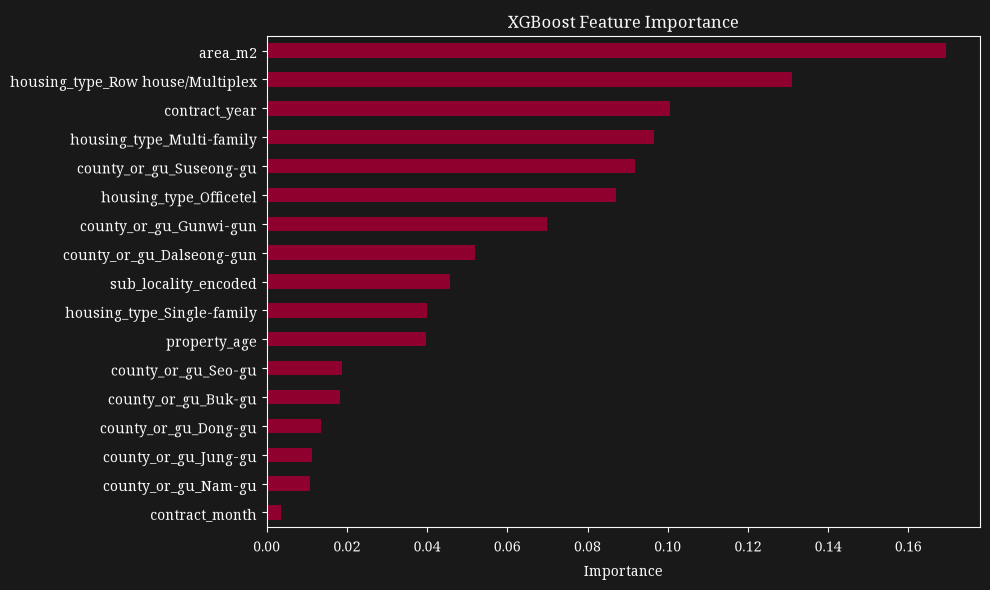

area_m2                             0.169383
housing_type_Row house/Multiplex    0.130993
contract_year                       0.100519
housing_type_Multi-family           0.096632
county_or_gu_Suseong-gu             0.091757
housing_type_Officetel              0.087209
county_or_gu_Gunwi-gun              0.069879
county_or_gu_Dalseong-gun           0.052039
sub_locality_encoded                0.045672
housing_type_Single-family          0.040067
property_age                        0.039790
county_or_gu_Seo-gu                 0.018677
county_or_gu_Buk-gu                 0.018177
county_or_gu_Dong-gu                0.013655
county_or_gu_Jung-gu                0.011388
county_or_gu_Nam-gu                 0.010712
contract_month                      0.003449
dtype: float32

In [61]:
importances = pd.Series(final_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
importances.plot(kind="barh", ax=ax, color=ACCENT)
ax.invert_yaxis()
ax.set_title("XGBoost Feature Importance")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.savefig("../reports/figures/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

importances

Feature importance rankings are sensitive to the metric used. `sub_locality_encoded` ranks 10th by `gain` (average improvement per split) but 1st by `total_cover` (total training rows affected across all its splits) and 3rd by `weight` (number of times used in a split). This reflects how each metric rewards different behavior: `gain` favors features used in fewer, more decisive splits (like a clean categorical dummy), while `weight` and `cover` favor features used repeatedly across many trees, which is how a continuous, information-dense feature like a target encoding tends to contribute. Both `gain` and `weight` are reported together, rather than relying on `gain` alone, which would understate `sub_locality_encoded`'s real role in the model.

In [62]:
booster = final_model.get_booster()

gain_scores = pd.Series(booster.get_score(importance_type="gain")).sort_values(ascending=False)
weight_scores = pd.Series(booster.get_score(importance_type="weight")).sort_values(ascending=False)

importance_comparison = pd.DataFrame({
    "gain_rank": gain_scores.rank(ascending=False).astype(int),
    "weight_rank": weight_scores.rank(ascending=False).astype(int),
}).sort_values("gain_rank")

importance_comparison

,gain_rank,weight_rank
area_m2,1,1
housing_type_Row house/Multiplex,2,7
contract_year,3,4
housing_type_Multi-family,4,13
county_or_gu_Suseong-gu,5,10
housing_type_Officetel,6,17
county_or_gu_Gunwi-gun,7,16
county_or_gu_Dalseong-gun,8,11
sub_locality_encoded,9,3
housing_type_Single-family,10,6


`area_m2` and `contract_year` rank highly by both `gain` and `weight`, confirming they are the most reliably important features regardless of measurement choice. Housing type indicators rank much higher by `gain` than `weight` across the board (e.g. Officetel: 6th vs. 17th), consistent with categorical dummies providing large, one-shot improvements in a small number of splits. `property_age`, `contract_month`, and `sub_locality_encoded` show the reverse pattern, ranking much higher by `weight` than `gain`, the model relies on them repeatedly for smaller, incremental refinements rather than any single decisive split. Both patterns reflect real model behavior, not an error, gain-based rankings alone would understate how much continuous, granular features like `sub_locality_encoded` actually contribute.

### Actual vs. Predicted

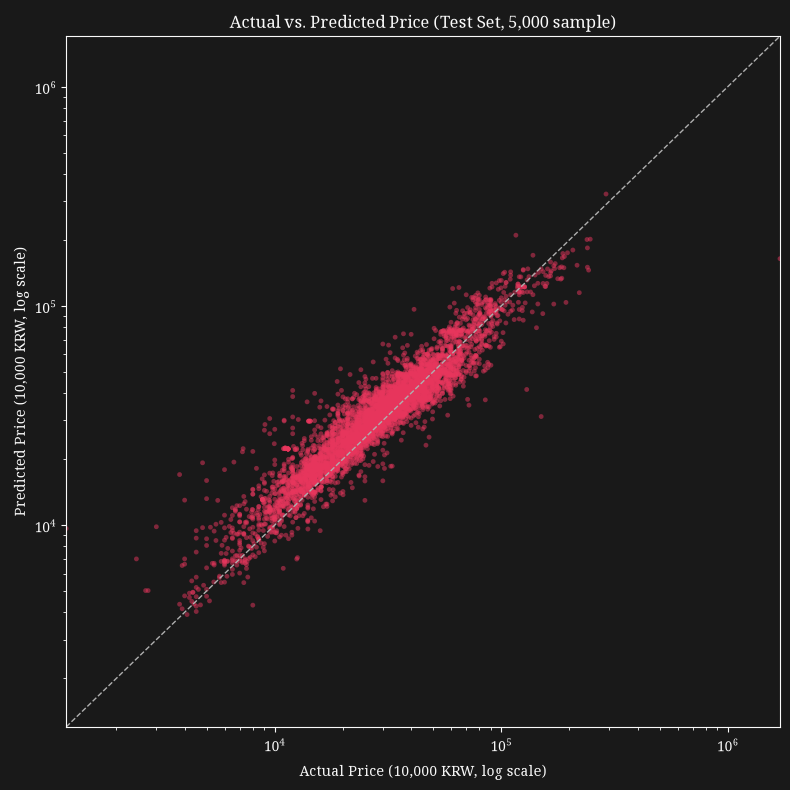

In [63]:
fig, ax = plt.subplots(figsize=(8, 8))
sample_idx = np.random.RandomState(42).choice(len(y_test_actual), size=5000, replace=False)

x_sample = y_test_actual.iloc[sample_idx]
y_sample = test_pred_actual[sample_idx]

point_color = "#E8365D"  # brighter red, used only in this plot
ax.scatter(x_sample, y_sample, alpha=0.5, s=12, color=point_color, edgecolors="none")

lims = [max(1, min(x_sample.min(), y_sample.min())), max(x_sample.max(), y_sample.max())]
ax.plot(lims, lims, color="#AFAFAF", linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Actual Price (10,000 KRW, log scale)")
ax.set_ylabel("Predicted Price (10,000 KRW, log scale)")
ax.set_title("Actual vs. Predicted Price (Test Set, 5,000 sample)")
plt.tight_layout()
plt.savefig("../reports/figures/actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

The actual-vs-predicted plot (log scale) shows tight agreement with the diagonal across nearly the full test price range, with no systematic over- or under-prediction bias in the dense middle of the distribution. Spread widens slightly at the low-price end, consistent with the higher percentage error found for smaller properties in the Single-family investigation. This closes model evaluation: XGBoost performs reliably across the bulk of the price range, with known, explained weak points (small-property location premiums, rare large properties) rather than unexplained failure.

## Model Persistence

The tuned XGBoost model is saved using `joblib`, along with the `sub_locality` encoding mapping and the global mean fallback value, both are required to preprocess any new data the same way before this model can predict on it. File size is checked before deciding how it will be shared, GitHub's browser upload rejects files over 25 MB.

In [64]:
import joblib
import os

joblib.dump(final_model, "../models/final_model.pkl")
joblib.dump({
    "sub_locality_encoding": locality_encoding,
    "global_mean_log_price": global_mean_log_price,
    "feature_cols": feature_cols,
}, "../models/preprocessing_artifacts.pkl")

model_size_mb = os.path.getsize("../models/final_model.pkl") / (1024 * 1024)
print(f"final_model.pkl size: {model_size_mb:.2f} MB")

final_model.pkl size: 20.08 MB


## Conclusions

This project built a model to predict Daegu residential property prices across all five housing types (Apartment, Single-family, Row house/Multiplex, Multi-family, Officetel) using 20 years of real transaction records. Three candidate models were compared using time-based cross-validation, XGBoost was selected over Random Forest with statistical backing (Wilcoxon signed-rank test, p=0.0059 across 10 folds), and over a linear baseline whose own diagnostics (severe multicollinearity before correction, non-normal residuals, a coefficient sign inversion for Officetel) confirmed real non-linear relationships in the data that only a tree-based model could capture.

On the held-out 2023-2024 test set, the final model achieves an overall MAPE of 19.6% (RMSE 12,084, MAE 5,881, in units of 10,000 KRW). Performance varies meaningfully by housing type: Officetel is predicted most reliably (MAPE 13.8%), likely due to its standardized, smaller unit sizes, while Single-family is the weakest (MAPE 62.8%), driven by two distinct causes rather than one, a genuine scarcity of large, high-value properties in the training data, and an inability to distinguish an individual small parcel's redevelopment value from its neighborhood's typical price, since location is only known at the district and sub-locality level, not by exact coordinates.

`area_m2` and `contract_year` are the model's most consistently important features across every importance metric checked. Location signal (`sub_locality_encoded`, county indicators) and housing type both matter substantially as well, though their apparent importance depends on which metric is used, categorical housing type indicators score highly on `gain` (large, decisive splits) while the continuous `sub_locality_encoded` scores highly on `weight` and `cover` (frequent, incremental use), both are real contributions, measured differently.

## Recommendations

- The model is most reliable for Apartment transactions (74% of the training data and the lowest-variance housing type in prior analysis), and can reasonably support automated or semi-automated price estimation for this segment.
- For Single-family properties, especially small (under ~50 m2) properties in central districts (Jung-gu, Dong-gu, Buk-gu) or unusually large properties (over ~1,000 m2), predictions should be treated as a rough reference only, not a substitute for manual appraisal, given the demonstrated redevelopment-value and data-scarcity issues specific to this segment.
- Future iterations of this model would benefit most from two additions, in order of expected impact: (1) precise property coordinates, to replace the current district/sub-locality granularity and directly capture the small-property location premium identified in this analysis, and (2) a disambiguated building-vs-unit area field for Single-family and Multi-family transactions, which the current data cannot resolve since `building_name` and `building_block` were dropped for being too sparse and high-cardinality to use directly.
- Given the very different price dynamics and data availability observed between housing types (particularly Single-family/Multi-family's whole-building area convention versus Apartment/Officetel/Row house's per-unit convention), a future version could test housing-type-specific models rather than one shared model, to see whether specialization improves the weakest segments without sacrificing the strong Apartment performance.

## Limitations

Several columns (`land_area_m2`, `land_ownership_area_m2`, `transaction_type`) were dropped due to structural missingness tied to specific housing types or a 2021 disclosure policy change, rather than imputed, real information from the original data is unavailable in this analysis as a result. Location is known only at the district and sub-locality level, no coordinates are available, limiting the model's ability to price individual parcels precisely, this is the primary driver of the Single-family segment's weaker performance. Prices are used as recorded and are not adjusted for inflation or macroeconomic conditions (interest rates, housing policy changes) across the 20-year period, so the model reflects nominal price patterns, not real, policy-adjusted ones. `construction_year` shows age heaping (imprecise rounding to nearby decades for older buildings), a known limitation of the recording process rather than a correctable error. Finally, whether Single-family/Multi-family transactions with unusually large recorded area represent legitimate whole-building sales or a per-unit/whole-building recording inconsistency could not be resolved with the columns available in this dataset.